## **Lab 4: From Deep Neural Networks to Convolutional Neural Networks**
---

**Read drive documentation**

In [30]:
!apt-get -qq install -y libarchive-tools
!mkdir -p /content/neu_raw  #new folder
!bsdtar -xf /content/NEU-CLS.rar -C /content/neu_raw

from pathlib import Path
import shutil

#define the classes
classes = {
    "Cr": "crazing",
    "In": "inclusion",
    "Pa": "patches",
    "PS": "pitted_surface",
    "RS": "rolled_in_scale",
    "Sc": "scratches",
}
counts = {name: 0 for name in classes.values()}

for image in Path("/content/neu_raw").rglob("*.bmp"):
    code = image.stem.split("_")[0]
    folder = Path("/content/NEU") / classes[code]
    folder.mkdir(parents=True, exist_ok=True)
    shutil.copy2(image, folder / image.name)
    counts[classes[code]] += 1

print(counts)
assert all(count == 300 for count in counts.values())

{'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted_surface': 300, 'rolled_in_scale': 300, 'scratches': 300}


---

**PART I — UNDERSTANDING IMAGE DATA**

6. **Import the Libraries**

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import (
 accuracy_score,
 classification_report,
 confusion_matrix,
 ConfusionMatrixDisplay
)

#Random Seed
torch.manual_seed(42)


7. **Check for CPU or GPU**

In [32]:
device = torch.device(
 "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

Device: cpu


---
8. **Image Processing**

In [33]:
transform = transforms.Compose([
 transforms.Grayscale(num_output_channels=1),
 transforms.Resize((64, 64)),
 transforms.ToTensor()
])

9. **Load the Data set**

In [34]:
#NEU/
#|
#+-- crazing/
#+-- inclusion/
#+-- patches/
#+-- pitted_surface/
#+-- rolled_in_scale/
#+-- scratches/
#Deep Learning
#Masoud Makrehchi
#Deep Learning - Masoud Makrehchi | Lab 4 | Page 5
dataset = datasets.ImageFolder(
 root="NEU",
 transform=transform #applies a transform to each image
)
print("Number of images:", len(dataset))
print("Classes:", dataset.classes)

Number of images: 1800
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled_in_scale', 'scratches']


---
10. **Inspect One Image**


In [35]:
image, label = dataset[0]
print("Image shape:", image.shape)
print("Class:", dataset.classes[label])

Image shape: torch.Size([1, 64, 64])
Class: crazing


11. **Display Images**

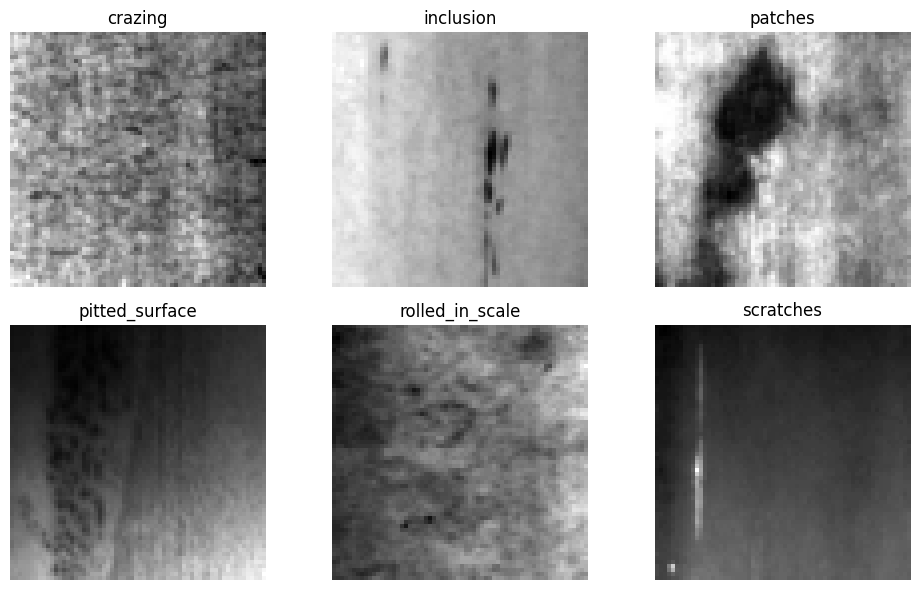

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, idx in zip(axes.flat, range(6)):
 image, label = dataset[idx * 300]
 ax.imshow(image.squeeze(), cmap="gray")
 ax.set_title(dataset.classes[label])
 ax.axis("off")
plt.tight_layout()
plt.show()


**Question 1.** Can you visually distinguish all six defect classes easily?
> Yes, each class can be distinguish from each other because of the different patters and textures. However, some classes might have similar image characteristics.

**Question 2.** Which defect classes appear most similar?
> From the visual inspection, crazing and rolled-in-scale might look similar due to similar contrast and gray-tone in some areas. Also, both exhibit irregular surface patters, making it hard to differentiate.

**Question 3.** Why might these similarities make classification difficult?
> Compared to other classes such as scratches and patches that have different contrast, the model might confuse or overalp the characteristics of the gray-tone and contrast, which might cause incorrect classification in crazing and rolled classes.

---

12. **Training, Validation, and Test Sets**


In [37]:
n = len(dataset)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
n_test = n - n_train - n_val
train_set, val_set, test_set = random_split(
 dataset,
 [n_train, n_val, n_test],
 generator=torch.Generator().manual_seed(42)
)

13. Create DataLoaders


In [38]:
batch_size = 32
train_loader = DataLoader(
 train_set,
 batch_size=batch_size,
 shuffle=True
)
val_loader = DataLoader(
 val_set,
 batch_size=batch_size,
 shuffle=False
)
test_loader = DataLoader(
 test_set,
 batch_size=batch_size,
 shuffle=False
)

**Question 4.** Why should the training data be shuffled?
> It is important to avoid bias and overfitting. By creating batches, the model learns individual characteristic of every batch and shuffling them prevents the model from learning an order.


**Question 5.** Why is shuffling less important for the test set?
> In the test stage is not important to shuffle the data since the model  is not learning, which does not change weights or parameters. The purpose of the test set is to measure the model's performance.


---

15. **Define the Deep Neural Network**


In [39]:
class DeepNN(nn.Module):
 def __init__(self):
    super().__init__()

    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 64, 256),
        nn.ReLU(),
        nn.Linear(256, 64),
        nn.ReLU(),
        nn.Linear(64, 6)
 ) #4096->256->64->6
 def forward(self, x):
   return self.network(x)

deep_model = DeepNN().to(device)
print(deep_model)

DeepNN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=6, bias=True)
  )
)


17. **Count the Parameters**

In [40]:
def count_parameters(model):
 return sum(
 p.numel()
 for p in model.parameters()
 if p.requires_grad
 )
print("DNN parameters:", count_parameters(deep_model))


DNN parameters: 1065670


**Question 6.** Why does the first layer contain so many parameters? Hint: 4096 × 256.
> The first layer contains many parameters because it needs to connect the 4096 input values to each of the 256 established neurons, which results in more than 1,000,000 weights and the 256 biases.

---

18. **Define Loss and Optimizer**


In [41]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
 deep_model.parameters(),
 lr=0.001
)

19. **Training Function**

In [42]:
def train_one_epoch(model, loader, optimizer, loss_fn):
  model.train()
  total_loss = 0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)
    loss = loss_fn(outputs, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_loss += loss.item()
    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

  return total_loss / len(loader), correct / total


20. **Validation Function**

In [43]:
def evaluate(model, loader, loss_fn):
 model.eval()
 total_loss = 0
 correct = 0
 total = 0

 with torch.no_grad():
    for images, labels in loader:
      images = images.to(device)
      labels = labels.to(device)

      outputs = model(images)
      loss = loss_fn(outputs, labels)

      total_loss += loss.item()
      predictions = outputs.argmax(dim=1)
      correct += (predictions == labels).sum().item()
      total += labels.size(0)

 return total_loss / len(loader), correct / total

21. **Train the Deep Network**


In [44]:
epochs = 20

dnn_train_loss = []
dnn_val_loss = []
dnn_train_acc = []
dnn_val_acc = []

for epoch in range(epochs):
  train_loss, train_acc = train_one_epoch(
    deep_model, train_loader, optimizer, loss_fn
  )

  val_loss, val_acc = evaluate(
    deep_model, val_loader, loss_fn
 )

  dnn_train_loss.append(train_loss)
  dnn_val_loss.append(val_loss)
  dnn_train_acc.append(train_acc)
  dnn_val_acc.append(val_acc)

  print(
    f"Epoch {epoch+1:02d} | "
    f"Train Acc: {train_acc:.3f} | "
    f"Val Acc: {val_acc:.3f}"
 )


Epoch 01 | Train Acc: 0.166 | Val Acc: 0.237
Epoch 02 | Train Acc: 0.224 | Val Acc: 0.215
Epoch 03 | Train Acc: 0.248 | Val Acc: 0.263
Epoch 04 | Train Acc: 0.271 | Val Acc: 0.337
Epoch 05 | Train Acc: 0.343 | Val Acc: 0.281
Epoch 06 | Train Acc: 0.338 | Val Acc: 0.370
Epoch 07 | Train Acc: 0.361 | Val Acc: 0.396
Epoch 08 | Train Acc: 0.355 | Val Acc: 0.352
Epoch 09 | Train Acc: 0.384 | Val Acc: 0.419
Epoch 10 | Train Acc: 0.454 | Val Acc: 0.489
Epoch 11 | Train Acc: 0.456 | Val Acc: 0.467
Epoch 12 | Train Acc: 0.481 | Val Acc: 0.419
Epoch 13 | Train Acc: 0.483 | Val Acc: 0.515
Epoch 14 | Train Acc: 0.507 | Val Acc: 0.363
Epoch 15 | Train Acc: 0.532 | Val Acc: 0.485
Epoch 16 | Train Acc: 0.537 | Val Acc: 0.548
Epoch 17 | Train Acc: 0.552 | Val Acc: 0.511
Epoch 18 | Train Acc: 0.575 | Val Acc: 0.519
Epoch 19 | Train Acc: 0.541 | Val Acc: 0.522
Epoch 20 | Train Acc: 0.562 | Val Acc: 0.493


22. **Plot the Learning Curves**

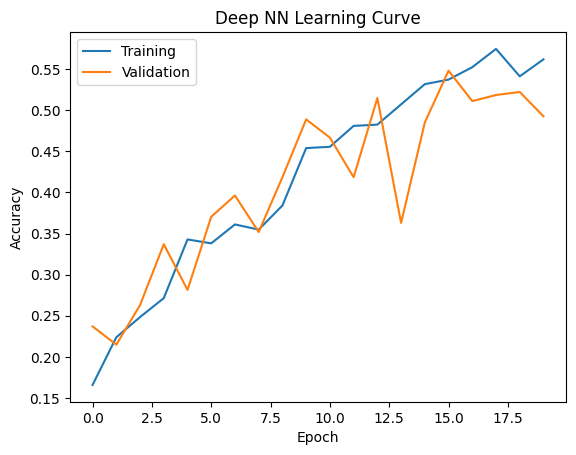

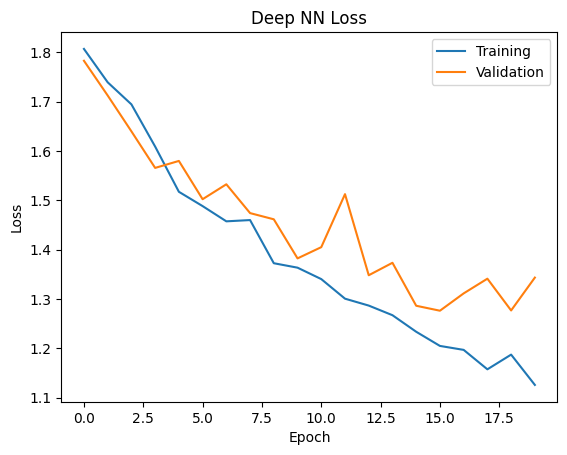

In [45]:
plt.plot(dnn_train_acc, label="Training")
plt.plot(dnn_val_acc, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep NN Learning Curve")
plt.legend()
plt.show()

plt.plot(dnn_train_loss, label="Training")
plt.plot(dnn_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep NN Loss")
plt.legend()
plt.show()

**Question 7.** Does the model appear to be learning?
> Yes, the model seems to be learning. On each epoch the training accuracy increases from 0.166 to 0.544 over the 20 defined epochs, while the training loss decreases, which is a clear indication that the model is improving/learning.

**Question 8.** Is there evidence of overfitting?
> There might be evidence of overfitting in the last epoch, where the validation accuracy drops to 0.467 and the traning loss decreases but the validation loss goes up. This might suggest that the model is learning the data better but generalizing the unseen data.

**Question 9.** At approximately which epoch does validation performance stop improving?
> Validation reach the best value at around epoch 19, but it decreases at epoch 20.

---

**PART III — CONVOLUTIONAL NEURAL NETWORK**

26. **Pooling**

In [46]:
nn.MaxPool2d(2)

#Define CNN

class CNN(nn.Module):
 def __init__(self):
  super().__init__()

  self.features = nn.Sequential(
      nn.Conv2d(1, 16, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(16, 32, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2)
 )
  self.classifier = nn.Sequential(
      nn.Flatten(),
      nn.Linear(64 * 8 * 8, 128),
      nn.ReLU(),
      nn.Linear(128, 6)
 )

 def forward(self, x):
  x = self.features(x)
  x = self.classifier(x)
  return x

29. **Create the CNN**


In [47]:
cnn_model = CNN().to(device)
print(cnn_model)
print("CNN parameters:", count_parameters(cnn_model))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=6, bias=True)
  )
)
CNN parameters: 548486



| Model | Parameters |
|-------|---------------|
| Deep NN |1065670|
| CNN |548486|



**Question 10.** Which model has more trainable parameters?
> The Deep NN has more trainable parameters (1065670) than the CNN (548486).

**Question 11.** Why can a CNN process an image effectively without connecting every input pixel to every hidden neuron?
> The CNN looks at regions of the image to obtain the patterns, while Deep NN connect the inputs to every neuron. Therefore, it has more parameters than CNN, which process the image efficiently with less parameters.
---

30. **Train the CNN**


In [48]:
cnn_optimizer = torch.optim.Adam(
 cnn_model.parameters(),
 lr=0.0005
)
cnn_train_loss = []
cnn_val_loss = []
cnn_train_acc = []
cnn_val_acc = []

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
      cnn_model, train_loader, cnn_optimizer, loss_fn
 )

    val_loss, val_acc = evaluate(
      cnn_model, val_loader, loss_fn
 )

    cnn_train_loss.append(train_loss)
    cnn_val_loss.append(val_loss)
    cnn_train_acc.append(train_acc)
    cnn_val_acc.append(val_acc)

    print(
      f"Epoch {epoch+1:02d} | "
      f"Train Acc: {train_acc:.3f} | "
      f"Val Acc: {val_acc:.3f}"
  )


Epoch 01 | Train Acc: 0.282 | Val Acc: 0.393
Epoch 02 | Train Acc: 0.449 | Val Acc: 0.448
Epoch 03 | Train Acc: 0.587 | Val Acc: 0.541
Epoch 04 | Train Acc: 0.637 | Val Acc: 0.537
Epoch 05 | Train Acc: 0.674 | Val Acc: 0.644
Epoch 06 | Train Acc: 0.728 | Val Acc: 0.630
Epoch 07 | Train Acc: 0.728 | Val Acc: 0.715
Epoch 08 | Train Acc: 0.764 | Val Acc: 0.733
Epoch 09 | Train Acc: 0.787 | Val Acc: 0.744
Epoch 10 | Train Acc: 0.778 | Val Acc: 0.774
Epoch 11 | Train Acc: 0.793 | Val Acc: 0.752
Epoch 12 | Train Acc: 0.799 | Val Acc: 0.807
Epoch 13 | Train Acc: 0.841 | Val Acc: 0.811
Epoch 14 | Train Acc: 0.854 | Val Acc: 0.789
Epoch 15 | Train Acc: 0.868 | Val Acc: 0.826
Epoch 16 | Train Acc: 0.867 | Val Acc: 0.867
Epoch 17 | Train Acc: 0.883 | Val Acc: 0.885
Epoch 18 | Train Acc: 0.890 | Val Acc: 0.863
Epoch 19 | Train Acc: 0.897 | Val Acc: 0.819
Epoch 20 | Train Acc: 0.907 | Val Acc: 0.859


31. **Compare Learning Curves**


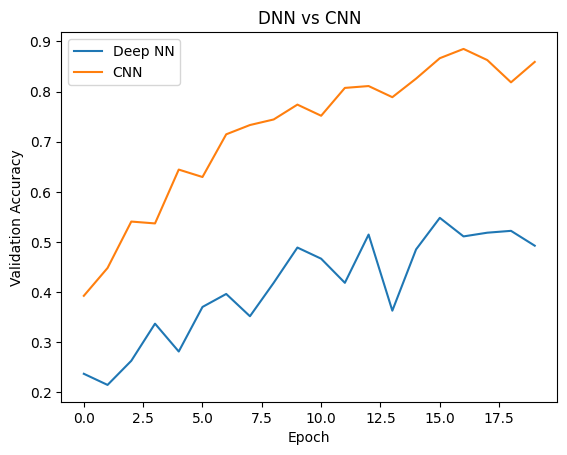

In [49]:
plt.plot(dnn_val_acc, label="Deep NN")
plt.plot(cnn_val_acc, label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("DNN vs CNN")
plt.legend()
plt.show()

**Question 12.** Which model learns faster?
> The validation accuracy of the CNN increases with fewer epochs than Deep NN, so the CNN learns faster.

**Question 13.** Which achieves better validation performance?
> The CNN achieves better validation performance than Deep NN. It reaches a value of 0.926 compared to the 0.467 value for the Deep NN.

**Question 14.** Which appears more stable during training?
> The CNN seems more stable during training which values fluctuate less as it keeps increasing.


---

**PART IV — FINAL MODEL EVALUATION**

32. **Evaluate on the Test Set**

In [50]:
dnn_test_loss, dnn_test_acc = evaluate(
 deep_model, test_loader, loss_fn
)
cnn_test_loss, cnn_test_acc = evaluate(
 cnn_model, test_loader, loss_fn
)
print("DNN Test Accuracy:", dnn_test_acc)
print("CNN Test Accuracy:", cnn_test_acc)

DNN Test Accuracy: 0.4740740740740741
CNN Test Accuracy: 0.8407407407407408


| Model | Test Accuracy |
|-------|---------------|
| Deep NN |0.4851852|
| CNN |0.9259259|

33. **Obtain All CNN Predictions**

In [51]:
all_labels = []
all_predictions = []

cnn_model.eval()

with torch.no_grad():
 for images, labels in test_loader:
    images = images.to(device)
    outputs = cnn_model(images)
    predictions = outputs.argmax(dim=1)

    all_labels.extend(labels.numpy())
    all_predictions.extend(predictions.cpu().numpy())


34. **Classification Report**


In [52]:
print(
 classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
 )
)

                 precision    recall  f1-score   support

        crazing       0.95      0.80      0.87        51
      inclusion       0.69      0.83      0.76        41
        patches       1.00      0.98      0.99        42
 pitted_surface       0.87      0.77      0.82        52
rolled_in_scale       0.76      0.93      0.84        41
      scratches       0.80      0.77      0.79        43

       accuracy                           0.84       270
      macro avg       0.85      0.85      0.84       270
   weighted avg       0.85      0.84      0.84       270



**Question 15.** Which class has the highest recall?
> Patches has the highest recall (1.00).

**Question 16.** Which class has the lowest recall?
> Inclusion has the lowest (0.85).

**Question 17.** Why might recall be particularly important in an industrial defect-detection system?
> Recall is important because it measures how many defects the model can detect, which is important for Industrial settings. If a defect is not detected it might cause financial loses and downtime, so it helps ensure that the defects are not missed.
---

35. **Confusion Matrix**


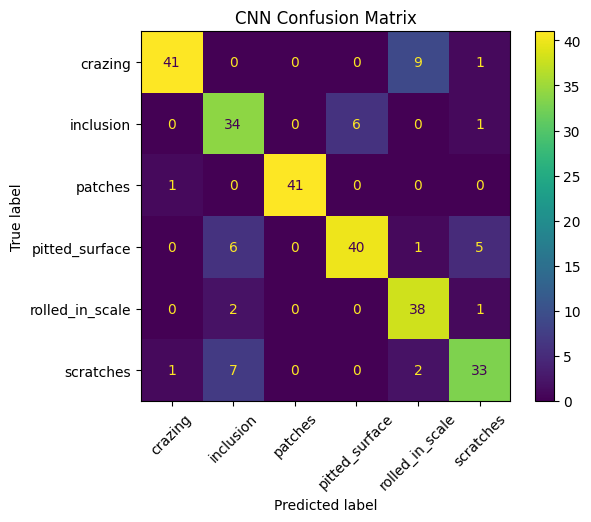

In [53]:
cm = confusion_matrix(all_labels, all_predictions)
display = ConfusionMatrixDisplay(
  confusion_matrix=cm,
  display_labels=dataset.classes
)

display.plot(xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.show()

**Question 18.** Which two defect types are most frequently confused?
> The most frequently confused defect types are inclusion (confused with pitted surface) and pitted surface (confused with scratches).

**Question 19.** Can you find a possible visual or mechanical explanation?
> A possible visual explanation for inclusion to be confused with a pitted surface is for the dark spots that both classes present. On the other hand, for the pitted surface to be confused with scratches might be to the grey-dark areas that both images show.
---

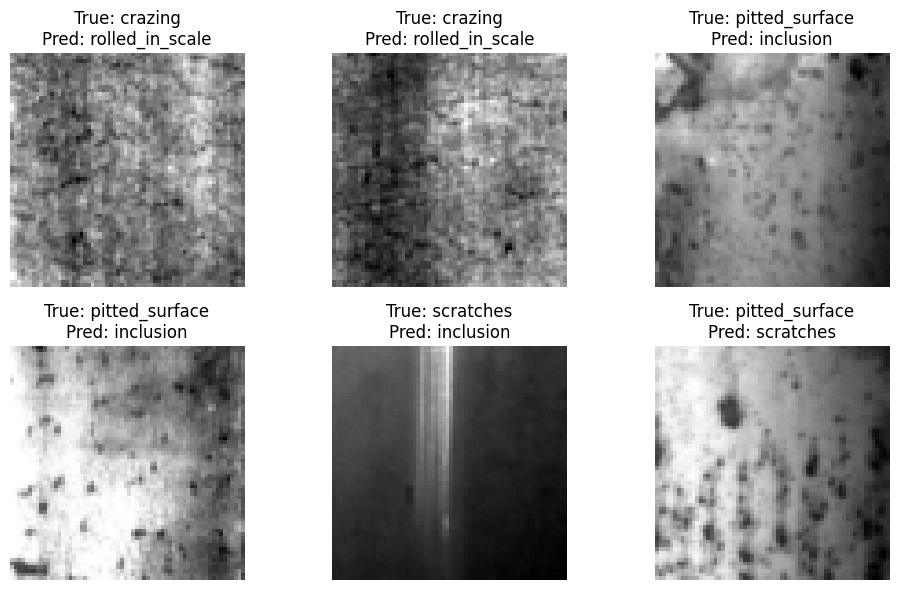

In [54]:
cnn_model.eval()
mistakes = []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        for image, true, pred in zip(images, labels, predictions):
            if true != pred:
                mistakes.append((image, true, pred))

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, item in zip(axes.flat, mistakes[:6]):
    image, true, pred = item
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(
        f"True: {dataset.classes[true]}\n"
        f"Pred: {dataset.classes[pred]}"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

37. **Engineering Error Analysis**

**Question 20.** Are the errors random, or do certain classes appear repeatedly?
> The errors do not seem to be random, as pitted surface is the most missclassified item as scratches. This shows that for the model is difficult to distinguish, which might be due to similar visual characteristic and grey patterns.

---

**PART V — WHY DID THE CNN PERFORM DIFFERENTLY?**

38. **Compare the Two Models**

| Characteristic | Deep NN | CNN |
|---|---|---|
| Input representation | Flattened pixels | 2D image |
| Uses spatial relationships | Limited | Yes |
| Local feature extraction | No | Yes |
| Weight sharing | No | Yes |
| Test accuracy | 46.7% | 92.6% |
| Parameter count | 1,065,670 | 548,486 |

---

**PART VI — BUILD A SMALL APPLICATION**


41. **From Model to Application**

In [57]:
from pathlib import Path
import torch

Path("results").mkdir(exist_ok=True)

torch.save(
    cnn_model.state_dict(),
    "results/cnn_model.pth"
)

print("CNN model weights saved!")

CNN model weights saved!


In [58]:
from google.colab import files

files.download("results/cnn_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:

%%writefile app.py

import gradio as gr
import torch

from PIL import Image

def predict_defect(image):
    image = transform(image)
    image = image.unsqueeze(0)
    image = image.to(device)

    cnn_model.eval()

    with torch.no_grad():
        outputs = cnn_model(image)
        probabilities = torch.softmax(outputs, dim=1)[0]

    results = {}

    for class_name, probability in zip(
        dataset.classes,
        probabilities.cpu().numpy()
    ):
        results[class_name] = float(probability)

    return results


app = gr.Interface(
    fn=predict_defect,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=6),
    title="Steel Surface Defect Classifier",
    description=(
        "Upload an image of a steel surface and "
        "the CNN will predict the defect type."
    )
)

app.launch()


Overwriting app.py


In [56]:
# Print filenames of images in the test set

for idx in test_set.indices:
    image_path, label = dataset.samples[idx]

    print(
        "Filename:", image_path.split("/")[-1],
        "| Class:", dataset.classes[label]
    )

Filename: Cr_122.bmp | Class: crazing
Filename: In_89.bmp | Class: inclusion
Filename: Cr_109.bmp | Class: crazing
Filename: Pa_210.bmp | Class: patches
Filename: RS_266.bmp | Class: rolled_in_scale
Filename: Cr_228.bmp | Class: crazing
Filename: In_229.bmp | Class: inclusion
Filename: Sc_166.bmp | Class: scratches
Filename: Pa_153.bmp | Class: patches
Filename: RS_225.bmp | Class: rolled_in_scale
Filename: Cr_166.bmp | Class: crazing
Filename: Pa_207.bmp | Class: patches
Filename: Cr_282.bmp | Class: crazing
Filename: PS_226.bmp | Class: pitted_surface
Filename: Cr_290.bmp | Class: crazing
Filename: Cr_271.bmp | Class: crazing
Filename: PS_231.bmp | Class: pitted_surface
Filename: Sc_9.bmp | Class: scratches
Filename: RS_184.bmp | Class: rolled_in_scale
Filename: RS_47.bmp | Class: rolled_in_scale
Filename: In_20.bmp | Class: inclusion
Filename: RS_145.bmp | Class: rolled_in_scale
Filename: In_59.bmp | Class: inclusion
Filename: PS_158.bmp | Class: pitted_surface
Filename: Sc_150.bmp 

45. **Test the Application**


| Image | True Class | Predicted Class | Confidence |
|---|---|---|---|
| image1 | Crazing | Crazing | 90% |
| image2 | rolled_in_scale| rolled_in_scale| 82%|
| image3 | patches| patches| 100%|

46. **Confidence Is Not Certainty**


**Question 21.** Find one example where the model gives substantial confidence to an incorrect prediction.
> One example where the model seems confidence is high is with pitted_surface that the CNN predicts as scratches, which is incorrect.

**Question 22.** Would you allow this classifier to automatically reject expensive manufactured components without human review? Explain.
> I would not allow the classifier to automatically reject a component without previous human intervention. Since this could lead to good components being rejected and cause financial losses.

---
**PART VII — EXPERIMENT**

48. **Record the Experiment**
My hyphotesis is that reducing the learning rate can improve the validation accuracy since the model can update in small steps, which could produce new results.

| Model | Validation Accuracy | Test Accuracy | Parameters |
|---|---|---|---|
| Original CNN | 0.926 | 0.952 | 548486|
| Modified CNN |0.959 | 0.968| 548486|


**Question 23.** Did the result support your hypothesis?
> Yes, the result showed that by changing the learning rate, the CNN improved its validation and test accuracy.

**Question 24.** Did the more complicated model necessarily perform better?
> Yes, it did performed better but it only increased the computational time.

----

49. **Final Engineering Reflection**

R1. Why is a fully connected neural network not naturally suited to image data?
> The fully connected neural network does not naturally process the how the pixels are connected to the image since it treats the inputs as a separate input.

R2. What is the advantage of applying the same convolutional filter at many image locations?
> The advantage is that the same filter can detect a feature on different parts of the image.

R3. What does pooling accomplish?
> Pooling reduces the size of the data that is being input but keeps the important information, which reduces computational time and is more efficient.

R4. Why should test data not be repeatedly used while modifying the CNN?
> Test data is only used to evaluate the performance of the final model. If it is used to modify the CNN, the model might get adapted to the test data causing overfitting.

R5. Why is a confusion matrix more informative than accuracy alone for this problem?
> The confussion matrix shows clearly what the model is confussing or correcting, while the accuracy only shows a percentage, which is less informative. Confusion matrix provides a better representation.

R6. Which failure would be more serious in an industrial setting: incorrectly rejecting a good component or accepting a defective component? Does the answer always remain the same?
> Accepting a defective component would be more serious since it causes safety issues and financial losses, but rejecting a component can be flag on the system and the review by operators.

R7. What additional evidence would you require before deploying this classifier on an actual production line?
> For this classifier, I would require more real production images of the actual production line, including common defects and also the manufacturing conditions of the plant.

